In [1]:
import re #Ψάχνει για Μοτίβα μέσα σε κείμενα θα την χρειαστώ για τα tickers
from datetime import datetime , date # Μετατρέπει κείμενα η αριθμούς σε ημερομηνίες αναγνωρίσημες
import numpy as np # Βασικό για αρηθμιτικούς Υπολογισμούς 
import pandas as pd # Δημιουργεί Πίνακες με στήλες και Γραμμές τα οποία κάνεις loc kai iloc
import yfinance as yf # Κατεβάζει δεδομένα απο Υahoo Finance
from scipy.stats import norm


def parse_option_ticker(symbol):
    """Σπάει ένα OCC ticker, π.χ. AAPL251219C00250000"""
    m = re.match(r"^([A-Z]{1,6})(\d{6})([CP])(\d{8})$", symbol.upper().strip())
    if m is None:
        raise ValueError("Μη έγκυρο ticker option. Παράδειγμα: AAPL251219C00250000")

    underlying, date_str, cp, strike_str = m.groups()

    return {
        "underlying": underlying, # Εδώ επιστρέφει το όνομα του ticker
        "expiry": datetime.strptime(date_str, "%y%m%d").date(),
        "type": "call" if cp == "C" else "put",
        "strike": int(strike_str) / 1000, #Μετατρέπει το κείμενο σε ακέραιο και διώχνει τα μηδενικα /1000
    }
# symbol.upper() an o χρήστης γράψει με πε΄ζά τα κάνει όλα κεφαλαία γιατι τα symbols ειναι με κεφαλαία 
# strip() Σβήνει κενά απο την αρ΄χη και απο το τέλος ώστε να μη προκύψει σφάλμα
# m = re.match(r"^([A-Z]{1,6})(\d{6})([CP])(\d{8})$" Ελέγχει αν το κείμενο ταιριάζει με ένα μοτίβο το r στην
# Αρχή υπάρχει για raw string το ^ Σημάινει οτι ξεκινά το κείμενο απο εκεί
# ([A-Z]{1,6}) Απο 1 εως 6 κεφαλαια γράμματα ( το underlying) απο το Α ΜΕΧΡΙ ΤΟ Ζ
# (\d{6}) ακριβώς 6 ψηφία η ημερομηνία 
# ([CP])	ένα γράμμα, C ή P 
#(\d{8})	ακριβώς 8 ψηφία (το strike)
# $	το τέλος του κειμένου, δεν επιτρέπονται άλλα μετά

In [2]:
# Στα Μοντελα Που Θα δουλέψουμε  θα χρειαστούμε να ονομάσουμε τα δεδομενα μας οποτε
# S = τρέχουσα τιμή της μετοχη΄ς απο ιστορικά δεδομένα
# σ= ετήσια διακύμανση η αλλιώς vollatility
# r = επιτόκιο χωρις ρίσκο ticker  ^IRX
#q = Dividen Yield μερίσματα του τελευταίου χρόνου.

In [3]:
ticker = "AAPL" # Ονομάζω Το Ticker και Ανάλογα αν το αλλάξω Αλλάζουν και τα δεδομένα μου παρακάτω
stock = yf.Ticker(ticker)
hist = stock.history(period = "1y") # Παίρνει τα δεδομένα για τον τελευταίο 1 χρόνο
hist.tail() # Δείχνει τα τελευταία 5 δεδομένα απο 10-07 μεχρι Σήμερα (10-13)  Του 2026

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-12 00:00:00-04:00,338.220001,342.630005,337.600006,340.970001,25900600,0.0,0.0
2026-10-13 00:00:00-04:00,344.670013,348.149994,340.739990,341.269989,38983800,0.0,0.0
2026-10-14 00:00:00-04:00,344.609985,347.089996,341.720001,342.959991,50061100,0.0,0.0
2026-10-15 00:00:00-04:00,346.950012,347.850006,341.600006,342.000000,39767300,0.0,0.0
2026-10-16 00:00:00-04:00,346.089996,347.820007,340.459991,343.459991,59895300,0.0,0.0


In [4]:
#Ακολουθεί η εύρεση της τιμής spot και φυσικά το Vollatility

In [5]:
spot = hist["Close"].iloc[-1] # Με το iloc[-1] παίρνει την τελευταία τιμή της στήλης Close

log_returns = np.log(hist["Close"] / hist["Close"].shift(1)).dropna() # shift(1) μετακινεί τη στήλη μια θέση, ωστε κάθε μέρα 
#Να την διαιρεί με την προηγούμενη. Το dropna() πετάει την πρώτη γραμμή που δεν θα εχει χθεσινή τιμή.
daily_vol = log_returns.std() # Υπολογίζει την ημερήσια τυπική απόκλιση των log_returns

annual_vol = daily_vol * np.sqrt(252) # Πολλαπλασιάζει με το 252 γιατι υπάρχουν περιπου 252 Trading Days.

print("Spot:", round(spot, 2))
print("Ημερήσια volatility:", round(daily_vol, 4))
print("Ετήσια volatility:", round(annual_vol, 4))



Spot: 343.46
Ημερήσια volatility: 0.0154
Ετήσια volatility: 0.2447


In [6]:
#Dividend Yield , Μάς χρειάζεται διότι , όταν η εταιρεία πληρώνει μερίσματα κατα την ημέρα του που κόβεται πέφτει η τιμή
#της μετοχής κατά το ποσό αυτό. Το χρειαζόμαστε για να υπολογίσουμε το q = μερίσματα ανα μετοχή / Τιμή Μετοχής 

In [7]:
divs = stock.dividends
divs

Date
1987-05-11 09:30:00-04:00    0.000536
1987-08-10 09:30:00-04:00    0.000536
1987-11-17 09:30:00-05:00    0.000714
1988-02-12 09:30:00-05:00    0.000714
1988-05-16 09:30:00-04:00    0.000714
                               ...   
2025-08-11 09:30:00-04:00    0.260000
2025-11-10 09:30:00-05:00    0.260000
2026-02-09 09:30:00-05:00    0.260000
2026-05-11 09:30:00-04:00    0.270000
2026-08-10 09:30:00-04:00    0.270000
Name: Dividends, Length: 92, dtype: float64

In [8]:
if len(divs)>0: # Το len ελέγχει πόσες εγραφφές εχει το Serie για να ελέξγει τις μετοχές που δεν δίνουν μερίσματα όπως  Tesla, Amazon
    cutoff= divs.index.max() - pd.Timedelta(days=365) #divs.index.max() Παίρνει την πιο πρόσφατη ημερομηνια
# Το pd.Timedelta(days=365) Είναι η διάρκεια ωστε να προσθέσεις η να αφαιρέσεις στην περίπτωση μας θα παρομυε ακριβως ενα έτος πριν
    div_last_year= divs[divs.index > cutoff].sum() # Συγκρίνει καθε ημερομηνία του divs me to cutoff επιστρέφει true / False kai αθροίζει μονο τα true kai τα αθροίζει
else:
    div_last_year = 0.0
div_yield= div_last_year/spot # Διαιρούμε τα μερίσματα του τελευταίου έτους με την spot τιμή παίρνω το [q]
print("Μερίσματα τελευταίου έτους:", round(div_last_year,2)) # round (....,2)) στρογυλοποιεί σε 2 δεκαδικά
print("Dividend Yield:", round(div_yield,4)) # Στρογγυλοποιεί σε 4 Δεκαδικά.

Μερίσματα τελευταίου έτους: 1.32
Dividend Yield: 0.0038


In [9]:
#Έυρεση του risk free rate

In [10]:
irx= yf.Ticker("^IRX").history(period="5d")["Close"].iloc[-1] # Παίρνουμε το ticker και απο όλες της στήλες
# Θέλουμε τα δεδομένα των τελευταίων 5 ημερών απο την στήλη Close και παίρνουμε την τελευταία με το Iloc[-1]
r= irx/100 # Το μετατρέπω σε δεκαδικό γιατι το δίνει ποσοστιαία 
print("Risk_Free rate:", round(r,4))

Risk_Free rate: 0.0407


In [11]:
# Έχοντας λοιπόν στην διάθεση μου όλα τα απαραίτητα δεδομένα θα δημιουρ΄γήσουμε μια έτοιμη συνάρτηση η οποια
# Θα μας εκτυπώνει δεδομένα για να συνεχίσουμε στο επόμενο βήμα που είναι αυτό της τιμολόγησης.


In [12]:
def get_market_data(ticker, period = "1y"):
    stock= yf.Ticker(ticker)
    hist = stock.history(period= period)
    if hist.empty:
        raise ValueError(f"Δεν βρέθηκαν δεδομένα για το {ticker}")
    spot= hist["Close"].iloc[-1]
    log_returns= np.log(hist["Close"]/hist["Close"].shift(1)).dropna()
    annual_vol = log_returns.std() *np.sqrt(252)

    divs = stock.dividends
    if len(divs)>0:
        cutoff = divs.index.max() - pd.Timedelta(days=365)
        div_yield= divs[divs.index > cutoff].sum()/spot
    else:
        div_yield= 0.0

    irx = yf.Ticker("^IRX").history(period="5d")["Close"].iloc[-1]
    r= irx/100

    return {
        "ticker" : ticker,
        "spot" : float(spot),
        "vol" : float(annual_vol),
        "r" : float(r),
        "q" : float(div_yield),
    }
    



 


In [13]:
opt = parse_option_ticker("AAPL271217C00065000")
opt


{'underlying': 'AAPL',
 'expiry': datetime.date(2027, 12, 17),
 'type': 'call',
 'strike': 65.0}

In [14]:
opt = parse_option_ticker("AAPL271217C00065000")
data = get_market_data(opt["underlying"], period="1y") # Καλεί την συνάρτηση get_market_data στο πεδίο του
#ονόματος ticker παίρνει apo to opt την γραμμή underlying giati einai ena dictionary
print(data)

{'ticker': 'AAPL', 'spot': 343.4599914550781, 'vol': 0.24472760389492762, 'r': 0.04070000171661377, 'q': 0.003843242394573476}


In [15]:
# Testing οτι λειτουργει και με αλλα ονόματα
opt = parse_option_ticker("AAPL271217C00065000")
opt

{'underlying': 'AAPL',
 'expiry': datetime.date(2027, 12, 17),
 'type': 'call',
 'strike': 65.0}

In [16]:
data= get_market_data(opt["underlying"], period = "1y")
data

{'ticker': 'AAPL',
 'spot': 343.4599914550781,
 'vol': 0.24472760389492762,
 'r': 0.04070000171661377,
 'q': 0.003843242394573476}

In [17]:
# O έλεγχος έχει γ΄ίνει και τώρα συνεχίζουμε με την αποτίμηση των Option

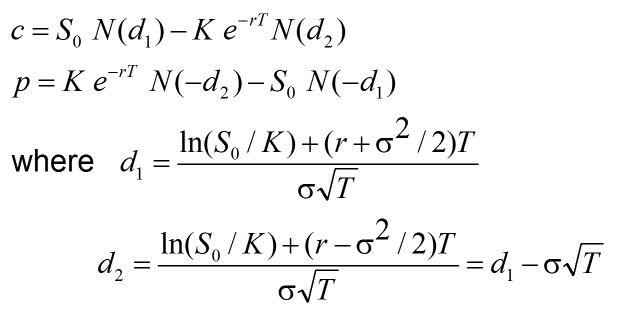

In [18]:
from IPython.display import Image , display
display(Image(filename= "BlackScholes.png"))

In [19]:
# Στο παραπάνω βλέπουμε την εξίσωση του BlackSCholesMerton και τις συνιστώσες της , της οποίες θα πάμε και θα υπολογίσομυε παρακάτω
# To mono poy paraleiptete alla tha to ipologisoume einai na afairesoume to q dld to merisma

In [20]:
days_to_expiry = (opt["expiry"] - date.today()).days # Παίρνει απο το Option που του δινεις το expiry δλδ την ημερομηνια βρίσκει την διαφορά με σήμερα
# Το date.today() δίνει το αποτέλεσμα ημερομηνία που τρέχεις τον κώδικα. ΤΟ . days κραταει μονο της ημέρες απο το διαστημα
T = days_to_expiry / 365

print("Ημέρες έως τη λήξη:", days_to_expiry)
print("T (σε έτη):", round(T, 4))

Ημέρες έως τη λήξη: 424
T (σε έτη): 1.1616


In [21]:
# Τώρα Χτίζουμε Ολοκληρωμένα την Συνάρτηση του Black_Scholes 


In [22]:
def black_scholes(S, K, T, r, q, sigma, option_type):
    if T <= 0:
        raise ValueError("Το option έχει λήξει (T <= 0).")
    # ΔΙΟΡΘΩΣΗ: όλο το αριθμητικό (ln(S/K) + (r-q+σ²/2)T) πρέπει να διαιρείται με σ√T
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        price = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    return price


In [23]:
# Εξήγηση της Συνάρτησης Βήμα Βήμα
# το d1 kai to d2 είναι ενδιάμεσοι αριθμοί που συνοψίζουν πόσο in the money ειναι το option λαμβανοντας υπόψη το vollatity και τον Χρόνο
# Το norm.cdf() ειναι κατά προσσέγιση η πιθανότητα το otpion να λήξει in the money υπο risk neutral μετρο
# Για το call η τιμη του ειναι: Παρούσα αξία της μετοχής που θα πάρεις - παρούσα αξια του strike , με σταθμισμενες πιθανότητες
# Για το put η τιμη λειτουργει αντίστροφα 

In [24]:
fair_price= black_scholes( S=data["spot"],
                           K= opt["strike"],
                           T=T,
                           r=data["r"],
                           q=data["q"],
                           sigma= data["vol"],
                           option_type=opt["type"])
print("Fair price (Black-Scholes):", round(fair_price,2))

Fair price (Black-Scholes): 279.93


In [25]:
# Greeks: μας δείχνουν πόσο ευαίσθητη είναι η τιμή του option σε αλλαγές των παραμέτρων
def bs_greeks(S, K, T, r, q, sigma, option_type):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf = norm.pdf(d1)
    disc_q, disc_r = np.exp(-q * T), np.exp(-r * T)

    gamma = disc_q * pdf / (S * sigma * np.sqrt(T))
    vega = S * disc_q * pdf * np.sqrt(T) / 100          # ανά 1% μεταβολή της volatility
    common = -S * disc_q * pdf * sigma / (2 * np.sqrt(T))

    if option_type == "call":
        delta = disc_q * norm.cdf(d1)
        theta = common - r * K * disc_r * norm.cdf(d2) + q * S * disc_q * norm.cdf(d1)
        rho = K * T * disc_r * norm.cdf(d2) / 100
    else:
        delta = disc_q * (norm.cdf(d1) - 1)
        theta = common + r * K * disc_r * norm.cdf(-d2) - q * S * disc_q * norm.cdf(-d1)
        rho = -K * T * disc_r * norm.cdf(-d2) / 100

    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta / 365, "rho": rho}


In [26]:
def price_option(symbol):
    """Δίνεις OCC symbol -> τυπώνει δεδομένα αγοράς, fair price, Greeks και σύγκριση με την αγορά."""
    opt = parse_option_ticker(symbol)
    symbol = symbol.upper().strip()

    days_to_expiry = (opt["expiry"] - date.today()).days
    if days_to_expiry <= 0:
        raise ValueError(f"Το option έληξε στις {opt['expiry']}. Δώσε symbol με μελλοντική λήξη.")
    T = days_to_expiry / 365

    data = get_market_data(opt["underlying"], period="1y")
    S, K = data["spot"], opt["strike"]

    price = black_scholes(S, K, T, data["r"], data["q"], data["vol"], opt["type"])
    g = bs_greeks(S, K, T, data["r"], data["q"], data["vol"], opt["type"])

    print("=" * 50)
    print(f"Option:       {symbol}")
    print(f"Underlying:   {opt['underlying']}   Τύπος: {opt['type'].upper()}")
    print(f"Strike:       {K:.2f}   Λήξη: {opt['expiry']}  ({days_to_expiry} ημέρες, T={T:.4f})")
    print("-" * 50)
    print(f"Spot (S):             {S:.2f}")
    print(f"Volatility (σ):       {data['vol']:.2%}  (ιστορική, 1 έτος)")
    print(f"Risk-free (r):        {data['r']:.2%}")
    print(f"Dividend yield (q):   {data['q']:.2%}")
    print("-" * 50)
    print(f"Fair price (Black-Scholes): {price:.2f}")
    print(f"Delta {g['delta']:.4f} | Gamma {g['gamma']:.4f} | Vega {g['vega']:.4f} | "
          f"Theta/ημέρα {g['theta']:.4f} | Rho {g['rho']:.4f}")

    # Σύγκριση με την τιμή της αγοράς (αν υπάρχει στο Yahoo Finance)
    try:
        chain = yf.Ticker(opt["underlying"]).option_chain(opt["expiry"].strftime("%Y-%m-%d"))
        table = chain.calls if opt["type"] == "call" else chain.puts
        row = table[table["contractSymbol"] == symbol]
        if row.empty:
            print("Δεν βρέθηκε το συγκεκριμένο contract στο Yahoo Finance.")
        else:
            row = row.iloc[0]
            mid = (row["bid"] + row["ask"]) / 2 if row["ask"] > 0 else row["lastPrice"]
            print("-" * 50)
            print(f"Αγορά: bid {row['bid']:.2f} | ask {row['ask']:.2f} | last {row['lastPrice']:.2f}")
            print(f"Implied vol (Yahoo): {row['impliedVolatility']:.2%}")
            diff = price - mid
            verdict = "ΥΠΕΡΤΙΜΟΛΟΓΗΜΕΝΟ στην αγορά" if diff < 0 else "ΥΠΟΤΙΜΟΛΟΓΗΜΕΝΟ στην αγορά"
            print(f"Μοντέλο - Αγορά (mid {mid:.2f}): {diff:+.2f}  ->  {verdict}")
    except Exception as e:
        print(f"(Δεν ήταν δυνατή η σύγκριση με την αγορά: {e})")
    print("=" * 50)

    return {"price": price, **g, **data, **opt}


In [27]:
symbol = input("Δώσε το option symbol (π.χ. AAPL261218C00250000): ")
result = price_option(symbol)


Δώσε το option symbol (π.χ. AAPL261218C00250000):  AAPL271217C00005000


Option:       AAPL271217C00005000
Underlying:   AAPL   Τύπος: CALL
Strike:       5.00   Λήξη: 2027-12-17  (424 ημέρες, T=1.1616)
--------------------------------------------------
Spot (S):             343.46
Volatility (σ):       24.47%  (ιστορική, 1 έτος)
Risk-free (r):        4.07%
Dividend yield (q):   0.38%
--------------------------------------------------
Fair price (Black-Scholes): 337.16
Delta 0.9955 | Gamma 0.0000 | Vega 0.0000 | Theta/ημέρα 0.0031 | Rho 0.0554
--------------------------------------------------
Αγορά: bid 0.00 | ask 0.00 | last 310.06
Implied vol (Yahoo): 0.00%
Μοντέλο - Αγορά (mid 310.06): +27.10  ->  ΥΠΟΤΙΜΟΛΟΓΗΜΕΝΟ στην αγορά
